<a href="https://colab.research.google.com/github/Anjan14/GridMO/blob/main/GridMO_v0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multi-objective trajectories on a grid: framework v0

**Goal.** Find the nondominated trajectories of an agent walking on a grid, where each objective adds up how close the agent is to something (the grass, the pool, a person) at every step. This notebook builds a 4 × 4 example environment and shows what the closeness formula produces.

**Contents.** 1 Environment · 2 Objective formula · 3 Counting trajectories · 4 Exact Pareto front · 5 Does the time weight matter? · 6 Simulated agents · 7 Moving people · 8 Larger grids · 9 Dataset for conditional generation · 10 Checks · 11 Open questions

**Conventions.** Cells are (row, col), 1-indexed, row 1 at the top. Moves are written `U D L R`, and `.` means *wait one step*. Every trajectory has exactly **T steps** (T + 1 positions), starts at **S** and is at **G** at step T. The agent may wait and may revisit cells. All of these are settings of `gridmo.GridEnv`.

The code lives in `gridmo.py`; the checks in `test_gridmo.py` (section 10).

In [1]:
import os, sys, time
try:                                   # Google Colab: files in Drive/GridMO
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = '/content/drive/MyDrive/GridMO'
except ImportError:                    # local Jupyter: files next to the notebook
    ROOT = os.getcwd()
sys.path.insert(0, ROOT)
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gridmo

plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.titlesize': 10})
pd.set_option('display.precision', 3)

Mounted at /content/drive


## 1. The environment

A 4 × 4 grid: start (4, 1), goal (1, 4), grass at (2, 2), pool at (3, 3). The pool and the grass are mirror images across the start–goal diagonal: routes that go up first pass the grass, routes that go right first pass the pool.

GridEnv(rows=4, cols=4, start=(4, 1), goal=(1, 4), T=10, landmarks={'grass': [(2, 2)], 'pool': [(3, 3)]}, impassable=[], obstacles=[], movers=[], allow_stay=True, diagonal=False, must_end_at_goal=True, absorbing_goal=False)


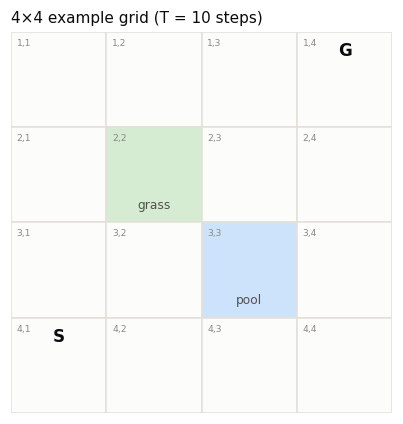

In [2]:
T = 10
env = gridmo.example_env(T=T)
print(env)
gridmo.plot_env(env, title='4×4 example grid (T = 10 steps)')
plt.show()

## 2. The objective formula

Initial Test Formula: $\sum_{t=0}^{n} 2^{-d} \times t$.

Read with a time index on $d$ (otherwise the sum is a constant):

$$o_{\text{grass}} \;=\; \frac{\sum_{t=0}^{T} w(t)\, k(d_t)}{\sum_{t=0}^{T} w(t)}, \qquad k(d) = 2^{-d}, \quad w(t) = t,$$

where $d_t$ is the distance at step $t$ from the agent to the grass. $k(d)$ is 1 on the landmark and halves with each cell of distance. Dividing by $\sum_t w(t)$ keeps values in $[0, 1]$, so they can be compared across horizons. The pool objective is the same with the pool as target.

Every part is a setting of `gridmo.Objective`, so a change to the formula is a one-line edit:

| setting | options | used here |
|---|---|---|
| `kernel` | `exp2` ($2^{-d}$), `exp` ($p^{-d}$), `inverse` ($1/(1+d)$), `linear`, `within` | `exp2` |
| `time_weight` | `linear` ($t$), `uniform` (1), `discount` ($\gamma^t$) | `linear` |
| `normalize` | `True` / `False` | `True` |
| `metric` | `manhattan`, `euclidean`, `chebyshev`, `walk` (around obstacles) | `manhattan` |

In [3]:
objectives = gridmo.example_objectives() # 2^-d, weight t, normalised
for objective in objectives:
    print(objective.describe())


# four hand-picked trajectories (T = 10)
examples = {
    'wait at the grass':      'UUR....URR',
    'wait at the pool':       'URR....UUR',
    'visit both':             'UUR.DR.UUR',
    'rush to G, wait there':  'UURURR....',
}

time_weights = {'w = t (as written)': 'linear', 'w = 1': 'uniform', 'w = 0.9^t': 'discount'}
rows = []


for name, moves in examples.items():
    trajectory = gridmo.from_moves(env, moves)
    row = {'trajectory': name, 'moves': moves}
    for label, time_weight in time_weights.items():
        grass, pool = gridmo.trajectory_values(
            env, gridmo.example_objectives(time_weight=time_weight), trajectory)[0]
        row[f'grass | {label}'] = grass
        row[f'pool | {label}'] = pool
    rows.append(row)
pd.DataFrame(rows).set_index('trajectory')

grass (max): sum_t t * 2^-d,  d = manhattan distance to grass / sum_t t
pool (max): sum_t t * 2^-d,  d = manhattan distance to pool / sum_t t


,moves,grass | w = t (as written),pool | w = t (as written),grass | w = 1,pool | w = 1,grass | w = 0.9^t,pool | w = 0.9^t
trajectory,,,,,,,
wait at the grass,UUR....URR,0.614,0.205,0.614,0.205,0.597,0.203
wait at the pool,URR....UUR,0.273,0.614,0.273,0.614,0.271,0.597
visit both,UUR.DR.UUR,0.391,0.459,0.432,0.398,0.444,0.358
"rush to G, wait there",UURURR....,0.227,0.145,0.295,0.159,0.325,0.165


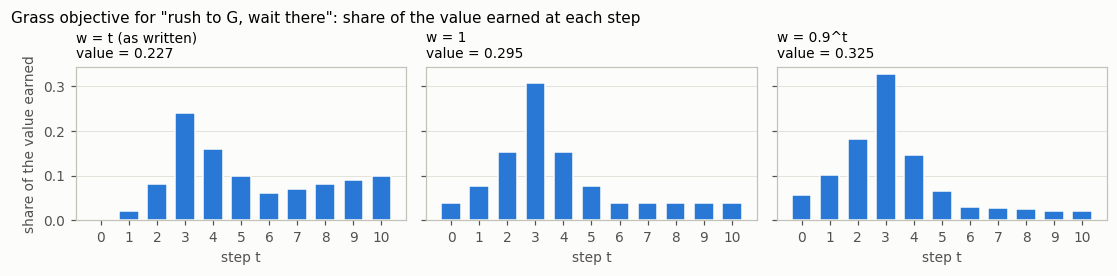

In [4]:
grass_variants = {label: gridmo.example_objectives(time_weight=time_weight)[0]
                  for label, time_weight in time_weights.items()}
gridmo.plot_step_contributions(env, grass_variants, gridmo.from_moves(env, 'UURURR....'))
plt.suptitle('Grass objective for "rush to G, wait there": share of the value earned at each step',
             x=0.01, ha='left', fontsize=10, y=1.02)
plt.show()

**Reading.** With $w(t) = t$ the start counts for nothing and the last steps count most, so *when* the agent is near the grass matters, not only how long. With $w = 1$ every step counts the same (total time near the grass); with $0.9^t$ early steps count most. Whether "later matters more" is intended is still open (section 11).

## 3. How many trajectories are there?

Counted exactly by dynamic programming (no enumeration needed). With waiting allowed the number grows fast with $T$. The last column checks the setup against a known sequence: without waiting or revisits there are 184 start-to-goal paths on a 4 × 4 grid (OEIS A007764).

In [5]:
rows = []
for steps in range(6, 17, 2):
    rows.append({
        'T': steps,
        'with waiting and revisits': gridmo.count_trajectories(gridmo.example_env(steps)),
        'simple paths (no waiting, no revisits)': len(gridmo.enumerate_trajectories(
            gridmo.example_env(steps, allow_stay=False), allow_revisit=False)),
    })
counts = pd.DataFrame(rows).set_index('T')
print('simple paths, all lengths:', counts.iloc[:, 1].sum())
counts

simple paths, all lengths: 184


,with waiting and revisits,"simple paths (no waiting, no revisits)"
T,,
6,20,20
8,896,36
10,23508,48
12,508464,48
14,10073492,32
16,190907264,0


## 4. The exact Pareto front (T = 10)

`gridmo.solve_front` finds the exact front without listing every trajectory: all objectives add up a per-step score that depends only on the cell and the step, so a partial trajectory that is dominated at some (cell, step) can never become nondominated and is dropped. Here it is checked against brute force over all 23,508 trajectories.

Many trajectories tie on the same objective vector (they differ only in *where* they wait, for example); `n_tied` counts them.

In [6]:
start = time.time()
front = gridmo.solve_front(env, objectives)
solver_seconds = time.time() - start

all_trajectories = gridmo.enumerate_trajectories(env)
start = time.time()
brute_force_front = gridmo.front_by_enumeration(env, objectives, all_trajectories)
brute_force_seconds = time.time() - start

def as_dict(f):
    return {tuple(np.round(v, 9)): c for v, c in zip(f.internal, f.counts)}

print(f'front: {len(front)} distinct objective vectors, {front.n_trajectories} trajectories on it')
print(f'solver {solver_seconds:.2f}s, brute force over {len(all_trajectories):,} trajectories '
      f'{brute_force_seconds:.2f}s, identical: {as_dict(front) == as_dict(brute_force_front)}')

pd.DataFrame({'grass': front.values[:, 0], 'pool': front.values[:, 1], 'n_tied': front.counts,
              'example moves': [gridmo.to_moves(env, r) for r in front.reps]})

front: 29 distinct objective vectors, 240 trajectories on it
solver 0.02s, brute force over 23,508 trajectories 0.05s, identical: True


,grass,pool,n_tied,example moves
0,0.273,0.614,4,URR....UUR
1,0.286,0.586,4,UR.R...UUR
2,0.291,0.577,8,URRUD..UUR
3,0.295,0.568,8,URR.UD.UUR
4,0.300,0.559,8,URR..UDUUR
5,0.305,0.550,8,URR...U.UR
6,0.309,0.541,8,UR.RUD.UUR
7,0.332,0.536,8,URURD..UUR
8,0.355,0.491,8,URUR.D.UUR
9,0.364,0.486,8,UR.URD.UUR


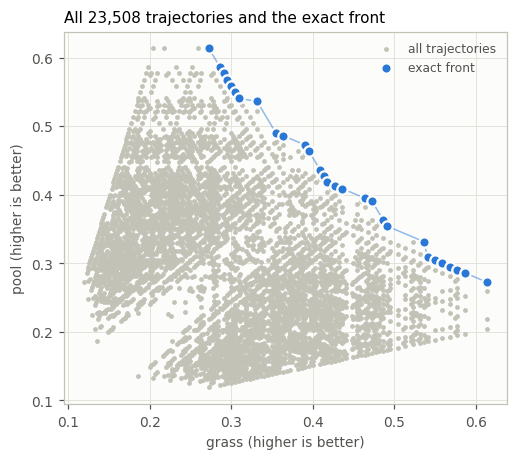

In [7]:
all_values = gridmo.trajectory_values(env, objectives, all_trajectories)
gridmo.plot_front(front, objectives, all_values=all_values,
                  title='All 23,508 trajectories and the exact front')
plt.show()

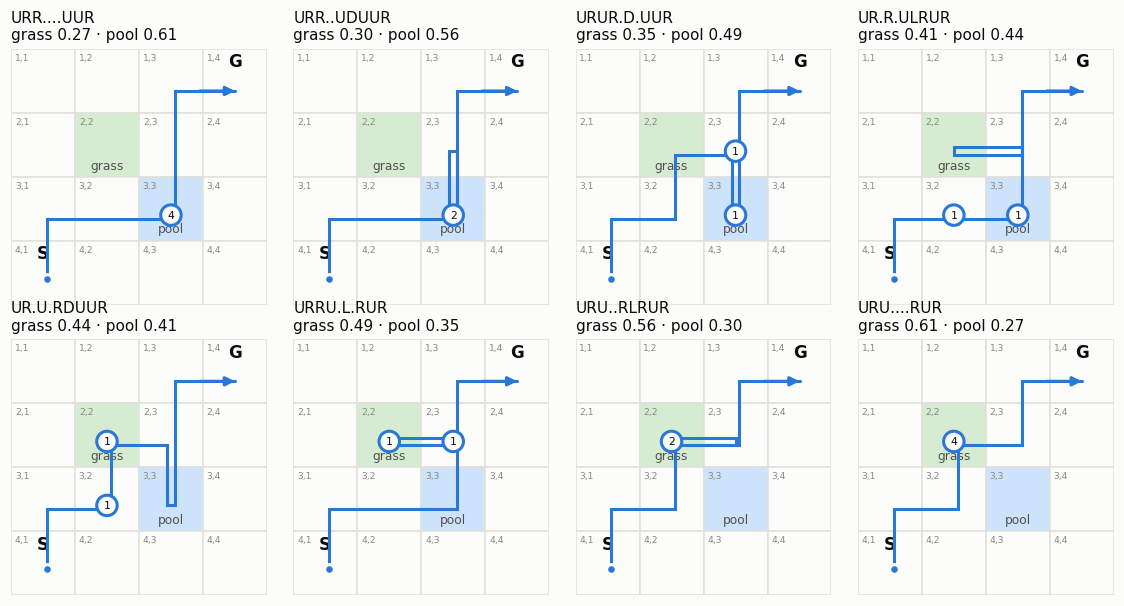

In [8]:
chosen = np.unique(np.linspace(0, len(front) - 1, 8).round().astype(int))
titles = [f'{gridmo.to_moves(env, front.reps[k])}\n'
          f'grass {front.values[k, 0]:.2f} · pool {front.values[k, 1]:.2f}' for k in chosen]
gridmo.plot_trajectory_panels(env, front.reps[chosen], titles=titles, ncols=4)
plt.show()

**Reading.** With spare steps the trade-off is *where the agent spends its waiting time*: at the grass, at the pool, or split between them. Circles show where the agent waits and for how many steps.

## 5. Does the time weight matter?

Same environment, three time weights. The weight does not change the most extreme trajectories here (the geometry forces them), but it changes how many distinct trade-offs exist, because a time weight makes the *order* of visits matter.

In [9]:
rows = []
for steps in (6, 8, 10, 12):
    grid = gridmo.example_env(steps)
    row = {'T': steps, 'trajectories': gridmo.count_trajectories(grid)}
    for label, time_weight in time_weights.items():
        row[f'front size | {label}'] = len(gridmo.solve_front(
            grid, gridmo.example_objectives(time_weight=time_weight)))
    rows.append(row)
pd.DataFrame(rows).set_index('T')

,trajectories,front size | w = t (as written),front size | w = 1,front size | w = 0.9^t
T,,,,
6,20,2,2,2
8,896,14,7,16
10,23508,29,11,34
12,508464,44,15,68


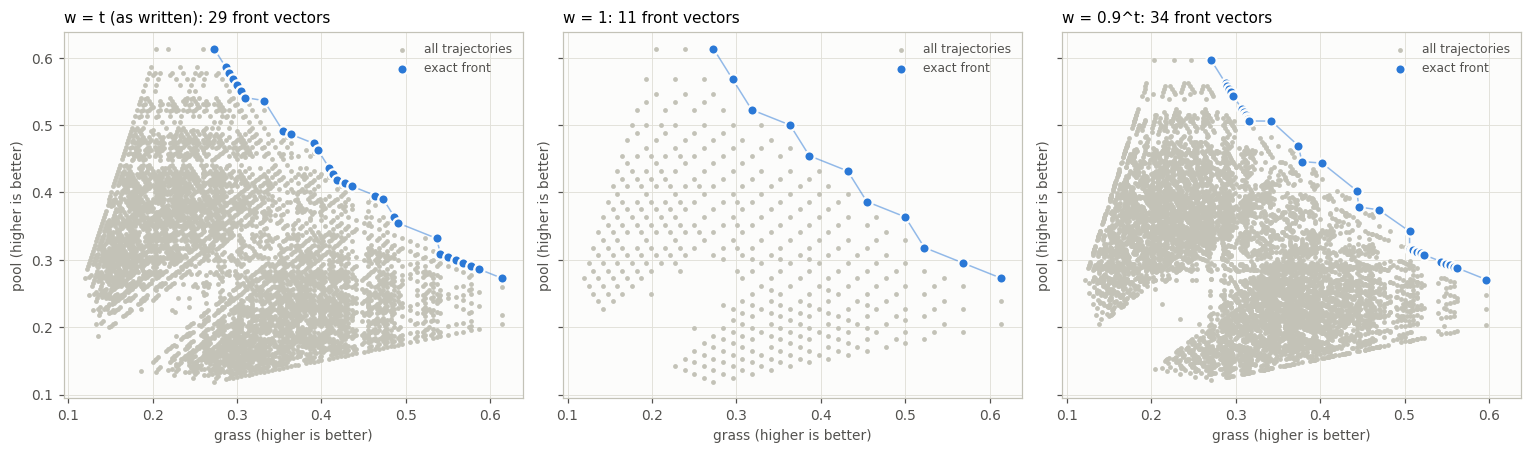

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True, sharey=True)
for ax, (label, time_weight) in zip(axes, time_weights.items()):
    weighted_objectives = gridmo.example_objectives(time_weight=time_weight)
    weighted_front = gridmo.solve_front(env, weighted_objectives)
    gridmo.plot_front(weighted_front, weighted_objectives,
                      all_values=gridmo.trajectory_values(env, weighted_objectives, all_trajectories),
                      ax=ax, title=f'{label}: {len(weighted_front)} front vectors',
                      annotate_counts=False)
plt.tight_layout()
plt.show()

## 6. Simulated agents

Four kinds of agent, all built from the same objectives:

* **Uniform random** — every valid trajectory equally likely (the null: what you get with no preferences at all).
* **Greedy (myopic)** — each agent has its own preference weights and, at every step, picks among moves that can still reach G in time by how close the next cell is to what it likes (softmax with a temperature).
* **Weighted-sum optimal** — maximises $w_1 o_1 + w_2 o_2$ over all trajectories. Sweeping the weights asks: *which front points can a linear preference ever produce?*
* **Chebyshev optimal** — minimises $\max_j w_j(\text{ideal}_j - o_j)$, the standard way to reach every front point.

weighted-sum agents reach 2 of 29 front vectors: [0, 28]
Chebyshev agents reach   29 of 29 front vectors
agent with weights 0.6 grass / 0.4 pool picks URU....RUR  (grass 0.614, pool 0.273)
Chebyshev agent with the same weights picks  URR.UL.RUR  (grass 0.473, pool 0.391)


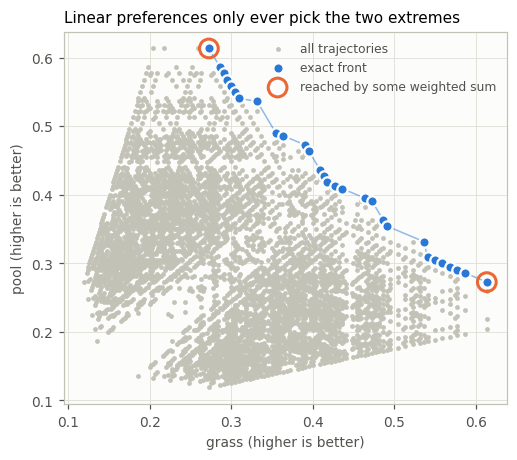

In [11]:
reached_by_weighted_sum = gridmo.sweep(front, 'weighted_sum', steps=1000)
reached_by_chebyshev = gridmo.sweep(front, 'chebyshev', steps=1000)
print(f'weighted-sum agents reach {len(reached_by_weighted_sum)} of {len(front)} front vectors: '
      f'{sorted(reached_by_weighted_sum)}')
print(f'Chebyshev agents reach   {len(reached_by_chebyshev)} of {len(front)} front vectors')

choice = gridmo.weighted_sum_choice(front, [0.6, 0.4])
print(f'agent with weights 0.6 grass / 0.4 pool picks {gridmo.to_moves(env, front.reps[choice])}  '
      f'(grass {front.values[choice, 0]:.3f}, pool {front.values[choice, 1]:.3f})')
choice = gridmo.chebyshev_choice(front, [0.6, 0.4])
print(f'Chebyshev agent with the same weights picks  {gridmo.to_moves(env, front.reps[choice])}  '
      f'(grass {front.values[choice, 0]:.3f}, pool {front.values[choice, 1]:.3f})')

gridmo.plot_front(front, objectives, all_values=all_values,
                  picks={'reached by some weighted sum': sorted(reached_by_weighted_sum)},
                  title='Linear preferences only ever pick the two extremes')
plt.show()

In [12]:
rng = np.random.default_rng(0)
n_agents = 2000
weight_vectors = gridmo.weight_grid(2, 1000)
agents = {
    'uniform random (null)': gridmo.sample_uniform(env, n_agents, rng),
    'greedy, temperature 0.05': gridmo.simulate_greedy(env, objectives, n_agents, rng,
                                                       temperature=0.05)[0],
    'greedy, temperature 0.5': gridmo.simulate_greedy(env, objectives, n_agents, rng,
                                                      temperature=0.5)[0],
    'weighted-sum optimal': front.reps[[gridmo.weighted_sum_choice(front, w) for w in weight_vectors]],
    'Chebyshev optimal': front.reps[[gridmo.chebyshev_choice(front, w) for w in weight_vectors]],
}
results = pd.DataFrame({name: gridmo.assess(env, objectives, trajectories, front)
                        for name, trajectories in agents.items()}).T
results['hv_ratio (worst-case ref)'] = [
    gridmo.assess(env, objectives, trajectories, front, ref='worst')['hv_ratio']
    for trajectories in agents.values()]
results[['n', 'valid_rate', 'on_front_rate', 'coverage', 'hv_ratio', 'hv_ratio (worst-case ref)']]

,n,valid_rate,on_front_rate,coverage,hv_ratio,hv_ratio (worst-case ref)
uniform random (null),2000.0,1.0,0.011,0.552,0.960,0.963
"greedy, temperature 0.05",2000.0,1.0,0.716,0.759,0.987,0.997
"greedy, temperature 0.5",2000.0,1.0,0.018,0.793,0.985,0.996
weighted-sum optimal,1001.0,1.0,1.000,0.069,0.346,0.850
Chebyshev optimal,1001.0,1.0,1.000,1.000,1.000,1.000


**Reading.** `on_front_rate` is the share of an agent's trajectories that are nondominated; `coverage` is the share of front vectors it reaches; `hv_ratio` is the hypervolume of what it produced divided by that of the exact front, measured from a reference point just below the front's worst values. The last column measures from the worst possible values instead; the weighted-sum agents score 0.35 one way and 0.85 the other, so the reference point is part of the metric and has to be reported.

The 4 × 4 grid is too small to separate methods: 2,000 random draws are almost 9% of all 23,508 trajectories, so the random null already lands on the front 1% of the time and reaches half of it. On the 8 × 8 grid in section 8 it reaches none of it. The same table will score a generative model later, with the uniform-random row as the null it has to beat.

The front bends inward because moving between the grass and the pool costs a step in the middle worth $0.5 + 0.5 = 1$, while staying at either is worth $1 + 0.25 = 1.25$. Any linear preference therefore commits to one landmark, and compromise trajectories are only produced by non-linear preferences such as Chebyshev.

## 7. Moving people (the harder version)

One person walks in a loop around the four centre cells, passing both the grass and the pool, one cell per step. A third objective, `near_person`, adds up closeness to the person at each step and is **minimised** (avoid people). Because the person moves, *when* the agent passes a cell matters even if every step is weighted equally, which is why the formula has to be written per time step.

The front below uses $w = t$. The timing example uses $w = 1$, so that grass and pool depend only on *which* cells are visited and any difference comes from the person alone.

In [13]:
loop_around_centre = [(2, 3), (3, 3), (3, 2), (2, 2)]
env_with_person = gridmo.example_env(T=8, movers=[gridmo.Mover('person', loop_around_centre, 'loop')])
objectives_with_person = gridmo.example_objectives(people=['person'])
for objective in objectives_with_person:
    print(objective.describe())

front_with_person = gridmo.solve_front(env_with_person, objectives_with_person)
front_without_person = gridmo.solve_front(gridmo.example_env(8), gridmo.example_objectives())
print(f'\nT = 8: {gridmo.count_trajectories(env_with_person)} trajectories, '
      f'front {len(front_with_person)} vectors ({front_with_person.n_trajectories} trajectories); '
      f'without the person the front had {len(front_without_person)} vectors')

# two trajectories that visit exactly the same cells, at different times (w = 1)
equal_weight_objectives = gridmo.example_objectives(people=['person'], time_weight='uniform')
trajectories_with_person = gridmo.enumerate_trajectories(env_with_person)
values_with_person = gridmo.trajectory_values(env_with_person, equal_weight_objectives,
                                              trajectories_with_person)
same_cells = {}
for index, trajectory in enumerate(trajectories_with_person):
    same_cells.setdefault(tuple(sorted(trajectory)), []).append(index)
group = max((g for g in same_cells.values() if len(g) > 1),
            key=lambda g: np.ptp(values_with_person[g, 2]))
good = group[np.argmin(values_with_person[group, 2])]
bad = group[np.argmax(values_with_person[group, 2])]
pd.DataFrame({'moves': [gridmo.to_moves(env_with_person, trajectories_with_person[k]) for k in (good, bad)],
              'grass': values_with_person[[good, bad], 0],
              'pool': values_with_person[[good, bad], 1],
              'near_person': values_with_person[[good, bad], 2]},
             index=['same cells, good timing', 'same cells, bad timing'])

grass (max): sum_t t * 2^-d,  d = manhattan distance to grass / sum_t t
pool (max): sum_t t * 2^-d,  d = manhattan distance to pool / sum_t t
near_person (min): sum_t t * 2^-d,  d = manhattan distance to person / sum_t t

T = 8: 896 trajectories, front 61 vectors (152 trajectories); without the person the front had 14 vectors


,moves,grass,pool,near_person
"same cells, good timing",URRLURUR,0.389,0.389,0.313
"same cells, bad timing",URUDRUUR,0.389,0.389,0.479


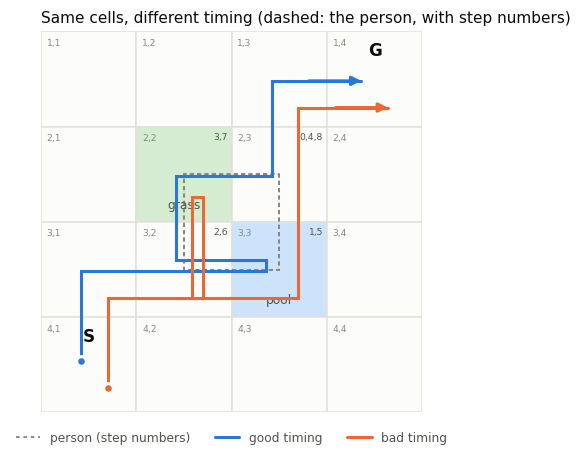

In [14]:
gridmo.plot_env(env_with_person, trajectories_with_person[[good, bad]],
                label_trajs=['good timing', 'bad timing'],
                title='Same cells, different timing (dashed: the person, with step numbers)')
plt.show()

## 8. Larger grids

A random 8 × 8 layout with walls, the two landmarks and one person on a random walk. Listing every trajectory is no longer practical, but the exact solver still runs.

T = 15, 5,483,000 trajectories; exact front: 229 vectors (906 trajectories) in 0.4s


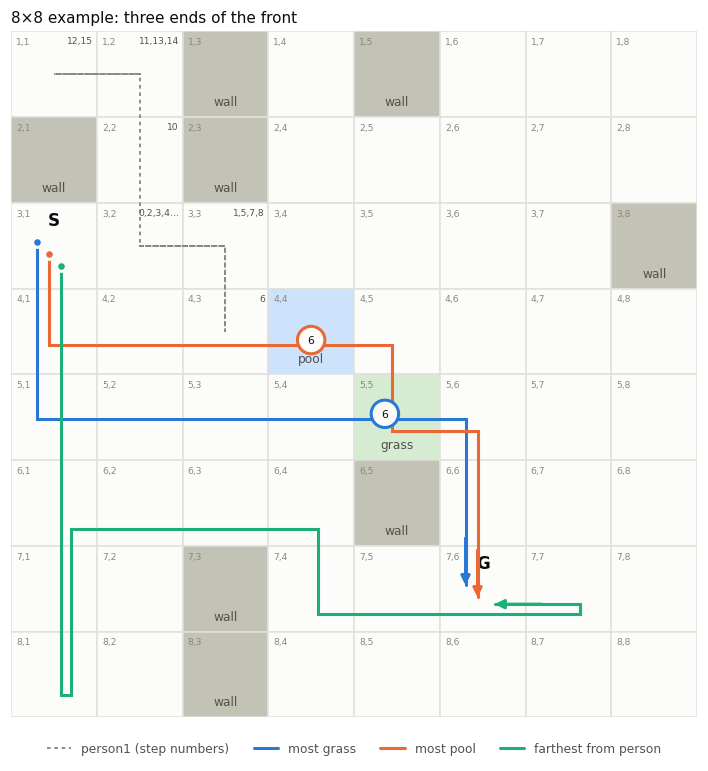

,n,valid_rate,on_front_rate,coverage,hv_ratio
uniform random (null),2000.0,1.0,0.000,0.000,0.674
"greedy, temperature 0.05",2000.0,1.0,0.149,0.179,0.944


In [15]:
rng = np.random.default_rng(0)
large_env = gridmo.random_env(rng, rows=8, cols=8, slack=6, n_obstacles=8, n_people=1)
large_objectives = gridmo.example_objectives(people=['person1'])
start = time.time()
large_front = gridmo.solve_front(large_env, large_objectives)
print(f'T = {large_env.T}, {gridmo.count_trajectories(large_env):,} trajectories; '
      f'exact front: {len(large_front)} vectors ({large_front.n_trajectories} trajectories) '
      f'in {time.time() - start:.1f}s')

ends_of_front = [int(np.argmax(large_front.values[:, 0])),
                 int(np.argmax(large_front.values[:, 1])),
                 int(np.argmin(large_front.values[:, 2]))]
gridmo.plot_env(large_env, large_front.reps[ends_of_front],
                label_trajs=['most grass', 'most pool', 'farthest from person'],
                title='8×8 example: three ends of the front')
plt.show()

large_agents = {
    'uniform random (null)': gridmo.sample_uniform(large_env, 2000, rng),
    'greedy, temperature 0.05': gridmo.simulate_greedy(large_env, large_objectives, 2000, rng,
                                                       temperature=0.05)[0],
}
pd.DataFrame({name: gridmo.assess(large_env, large_objectives, trajectories, large_front)
              for name, trajectories in large_agents.items()}).T[
    ['n', 'valid_rate', 'on_front_rate', 'coverage', 'hv_ratio']]

In [16]:
# how the exact solver scales (one random layout per size, one person, 3 objectives)
rows = []
for size, slack, walls in [(6, 4, 4), (8, 6, 8), (10, 8, 12)]:
    grid = gridmo.random_env(np.random.default_rng(7), rows=size, cols=size, slack=slack,
                             n_obstacles=walls, n_people=1)
    start = time.time()
    size_front = gridmo.solve_front(grid, gridmo.example_objectives(people=['person1']))
    rows.append({'grid': f'{size}×{size}', 'T': grid.T,
                 'trajectories': f'{gridmo.count_trajectories(grid):.2e}',
                 'front vectors': len(size_front), 'seconds': round(time.time() - start, 1)})
pd.DataFrame(rows).set_index('grid')

,T,trajectories,front vectors,seconds
grid,,,,
6×6,12,1.63e+05,180,0.1
8×8,16,1.01e+07,657,1.5
10×10,18,5.06e+08,4204,34.1


**Reading.** With three objectives and a moving person the front grows to thousands of vectors and the exact solver slows down quickly. That is the opening for a learned generator: produce good trajectories for a new map faster than exact search, scored against the exact front where it can still be computed.

## 9. A dataset for conditional generation ("environment given → produce plans")

Each record holds one random environment, the objective settings, the exact front (one representative trajectory per front vector, with how many trajectories tie it) and a uniform random sample labelled **P+** (nondominated) or **P−** (dominated). `gridmo.env_to_tensor` turns an environment into arrays a neural network can take as input.

In [17]:
os.makedirs('data', exist_ok=True)
rng = np.random.default_rng(42)
start = time.time()
records = gridmo.make_dataset(
    20, rng, lambda grid: gridmo.example_objectives(people=['person1']),
    env_kwargs=dict(rows=6, cols=6, slack=4, n_obstacles=4, n_people=1), n_random=50)
gridmo.save_jsonl(records, 'data/grid_dataset_v0.jsonl')
print(f'{len(records)} environments in {time.time() - start:.1f}s -> data/grid_dataset_v0.jsonl')



summary = pd.DataFrame([
    {'T': record['env']['T'],
     'trajectories': f"{int(record['n_trajectories']):.2e}",
     'front vectors': len(record['front']),
     'P+ share in random sample': np.mean([x['label'] == 'P+' for x in record['random']])}
    for record in records])
print(summary.describe().loc[['mean', 'min', 'max']].round(3))



first_record = records[0]
first_entry = first_record['front'][0]

print('\nrecord keys:', list(first_record))
print('first front entry:', first_entry['moves'], [round(v, 4) for v in first_entry['values']],
      'n_tied', first_entry['n_tied'])

tensors = gridmo.env_to_tensor(gridmo.GridEnv.from_dict(first_record['env']))

print('tensor shapes:', {name: array.shape for name, array in tensors.items()})

20 environments in 3.0s -> data/grid_dataset_v0.jsonl
          T  front vectors  P+ share in random sample
mean  10.55         189.95                      0.019
min   10.00          22.00                      0.000
max   12.00         877.00                      0.120

record keys: ['env', 'objectives', 'n_trajectories', 'front', 'random']
first front entry: UUURRU.... [0.0109, 0.0219, 0.0193] n_tied 5
tensor shapes: {'static': (5, 6, 6), 'movers': (11, 1, 6, 6)}


**How a generator plugs in.** Input: `gridmo.env_to_tensor(env)`. Output: move strings. Score: `gridmo.assess(env, objectives, gridmo.from_moves(env, moves), gridmo.solve_front(env, objectives))`, next to the uniform-random and greedy rows above. Generating *trajectories* (decisions) and computing their objectives keeps every generated plan real by construction, a lesson from the earlier Gen-MOR work.

## 10. Checks

`test_gridmo.py` holds 51 checks fixed before the framework was written: trajectory counts, the 184 simple paths, front sizes recorded from an independent brute-force script, the exact solver against brute force (several kernels, time weights, random layouts with people and walls), the uniform sampler, hypervolume, validity checks and JSON round trips.

In [18]:
import subprocess, importlib.util
if importlib.util.find_spec('pytest') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pytest'])
check = subprocess.run([sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_gridmo.py'],
                       capture_output=True, text=True, cwd=ROOT)
print(check.stdout[-600:] or check.stderr[-600:])

...................................................                      [100%]
51 passed in 3.81s



## 11. Open questions

1. **Formula.** Is it $\sum_t t \cdot 2^{-d_t}$ (later steps count more) or $\sum_t 2^{-d_t}$ (every step equal)? Should values be normalised to $[0, 1]$?
2. **0.6 and 0.4.** Example objective values, or an agent's preference weights? (With linear weights, agents only ever pick the two extreme trajectories; section 6.)
3. **Steps.** What fixed number of steps $T$? Must the agent be at the goal at step $T$, and may it wait or backtrack?
4. **"Count time step".** A separate objective (e.g. arrival time, available as `Objective(kind='time')`), or just the $t$ in the formula?
5. **Landmarks.** Can the agent step onto the pool? (`impassable=['pool']`.) Euclidean or Manhattan distance?
6. **People.** How do they move (fixed routes, random walks)? Does the agent know where they will be? What does "the human can see" mean?
7. **Conditional generation.** What varies between environments (size, landmark positions, walls, people)? Should the model output one trajectory per preference, or the whole front?

## Next steps

* Settle the formula and the setting (questions above), then set them in `example_objectives`.
* Grow the dataset (more and larger environments) and pick a first conditional generator (e.g. a small sequence model over moves, conditioned on `env_to_tensor`).
* Score it with `gridmo.assess` against the exact front, the uniform-random null and the greedy agents.